In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Find the project root (works whether the notebook runs from analysis/ or the root)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / ".env").exists() else Path.cwd().parent
load_dotenv(PROJECT_ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5433/{os.environ['POSTGRES_DB']}"
)


def q(sql):
    """Run a SQL query against the warehouse and return the result as a table."""
    return pd.read_sql(sql, engine)

## 1. What share of delivered orders arrive late?

In [2]:
q("""
SELECT
    COUNT(*)                              AS delivered_orders,
    ROUND(100.0 * AVG(is_late::int), 1)   AS pct_late
FROM analytics.fct_order_delivery
""")

,delivered_orders,pct_late
0,96470,6.8


**Finding:** Of 96,470 delivered orders, 6.8% (about 6,500) arrived after the
estimated delivery date, so roughly 93% were on time. On its own this number
doesn't tell us whether performance is good or bad — it needs context: a target,
a trend over time, and how severe and how widespread the delays are. The next
questions provide that context.

## 2. How did the late-delivery rate change month by month?

,purchase_month,orders,pct_late
0,2016-10-01,265,0.8
1,2017-01-01,750,2.9
2,2017-02-01,1653,3.0
3,2017-03-01,2546,4.6
4,2017-04-01,2303,6.6
5,2017-05-01,3545,3.0
6,2017-06-01,3135,3.0
7,2017-07-01,3872,2.8
8,2017-08-01,4193,2.9
9,2017-09-01,4150,4.4


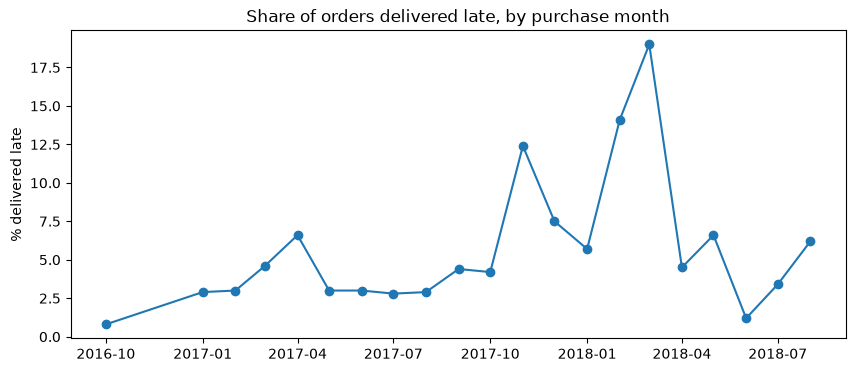

In [3]:
monthly = q("""
SELECT
    purchase_month,
    COUNT(*)                              AS orders,
    ROUND(100.0 * AVG(is_late::int), 1)   AS pct_late
FROM analytics.fct_order_delivery
GROUP BY purchase_month
HAVING COUNT(*) >= 100
ORDER BY purchase_month
""")

ax = monthly.plot(x="purchase_month", y="pct_late", marker="o", legend=False, figsize=(10, 4))
ax.set_title("Share of orders delivered late, by purchase month")
ax.set_ylabel("% delivered late")
ax.set_xlabel("")

(PROJECT_ROOT / "docs").mkdir(exist_ok=True)
ax.figure.savefig(PROJECT_ROOT / "docs" / "monthly_late_rate.png", dpi=150, bbox_inches="tight")

monthly

**Finding:** In most months, 3–5% of orders were delivered late. Three months
stand out: November 2017 (12.4%), February 2018 (14.1%) and March 2018 (19.0%).

The November spike coincides with a jump in order volume (~4,500 in October
to ~7,300), consistent with a Black Friday capacity crunch. February–March 2018
is different: volume stayed flat at around 7,000 orders per month, the same as
January (5.7% late). And from April 2018 onwards the late rate fell back to
normal levels even though volume remained above 6,000 orders a month.

So order volume alone does not explain the 2018 spike. The next question is
what changed in those two months — which part of the delivery chain caused it.

## 3. Were late deliveries caused by sellers or by carriers?

,purchase_month,seller_late,carrier_late,unknown
0,2016-10-01,2,0,0
1,2017-01-01,6,16,0
2,2017-02-01,29,20,0
3,2017-03-01,29,87,0
4,2017-04-01,46,105,0
5,2017-05-01,32,74,0
6,2017-06-01,35,60,0
7,2017-07-01,21,87,0
8,2017-08-01,35,87,0
9,2017-09-01,45,136,1


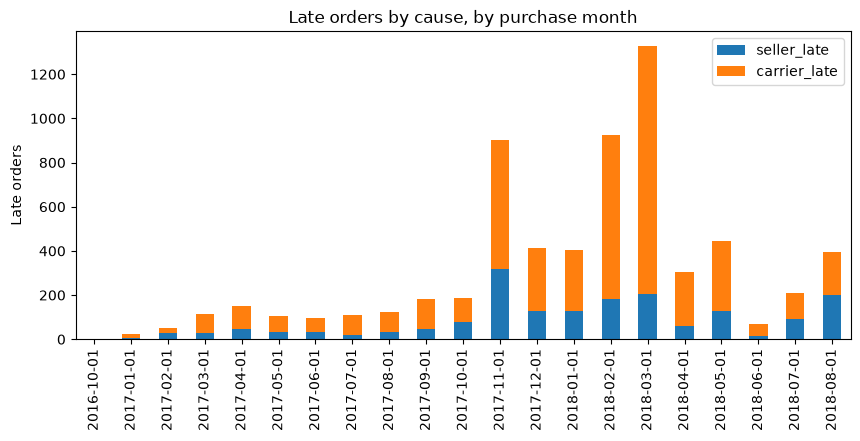

In [4]:
causes = q("""
SELECT
    purchase_month,
    COUNT(*) FILTER (WHERE delay_cause = 'seller')   AS seller_late,
    COUNT(*) FILTER (WHERE delay_cause = 'carrier')  AS carrier_late,
    COUNT(*) FILTER (WHERE delay_cause = 'unknown')  AS unknown
FROM analytics.fct_order_delivery
GROUP BY purchase_month
HAVING COUNT(*) >= 100
ORDER BY purchase_month
""")

ax = causes.plot(x="purchase_month", y=["seller_late", "carrier_late"],
                 kind="bar", stacked=True, figsize=(10, 4))
ax.set_title("Late orders by cause, by purchase month")
ax.set_ylabel("Late orders")
ax.set_xlabel("")
ax.figure.savefig(PROJECT_ROOT / "docs" / "late_orders_by_cause.png", dpi=150, bbox_inches="tight")

causes

In [5]:
rates = q("""
SELECT
    purchase_month,
    COUNT(*)                                                            AS orders,
    ROUND(100.0 * AVG((delay_cause = 'seller')::int), 1)                AS seller_late_pct,
    ROUND(100.0 * AVG((delay_cause = 'carrier')::int), 1)               AS carrier_late_pct
FROM analytics.fct_order_delivery
WHERE purchase_month BETWEEN '2017-10-01' AND '2018-05-01'
GROUP BY purchase_month
ORDER BY purchase_month
""")
rates

,purchase_month,orders,seller_late_pct,carrier_late_pct
0,2017-10-01,4478,1.8,2.4
1,2017-11-01,7288,4.4,8.0
2,2017-12-01,5513,2.3,5.2
3,2018-01-01,7069,1.8,3.9
4,2018-02-01,6555,2.8,11.3
5,2018-03-01,7003,2.9,16.0
6,2018-04-01,6798,0.9,3.6
7,2018-05-01,6749,1.9,4.7


**Finding:** Looking at counts alone is misleading, because months with more
orders naturally have more late orders. Comparing late *rates* gives a clearer
picture — and shows the two spikes were different kinds of problem:

- **November 2017 (whole-chain capacity problem):** order volume jumped 63%
  versus October, and both seller-caused (1.8% → 4.4%) and carrier-caused
  (2.4% → 8.0%) late rates rose sharply.
- **February–March 2018 (transport problem):** volume was flat, seller-caused
  lateness rose only slightly (1.8% → 2.9%), but carrier-caused lateness
  quadrupled (3.9% → 16.0%). Carrier rates rose about 11 times more than
  seller rates.
- **August 2018:** seller delays matched carrier delays in count for the first
  time — a new pattern worth monitoring.

**Next steps:** identify sellers who are repeatedly late; break carrier delays
down by region; investigate what happened in the carrier network in early 2018.
The dataset does not name the carrier, so carrier-level analysis would require
data from the logistics partner.

## 4. Where were carrier delays worst?

,customer_state,jan_orders,jan_carrier_late_pct,febmar_orders,febmar_carrier_late_pct
0,SP,2975,1.8,5603,6.5
1,RJ,850,10.2,1743,29.4
2,MG,846,1.5,1646,11.2
3,RS,367,6.5,770,13.9
4,PR,371,0.8,704,9.1
5,SC,311,8.0,501,17.2
6,BA,228,4.4,443,22.8
7,DF,135,0.7,317,10.4
8,GO,144,3.5,287,16.4
9,ES,145,6.2,282,23.0


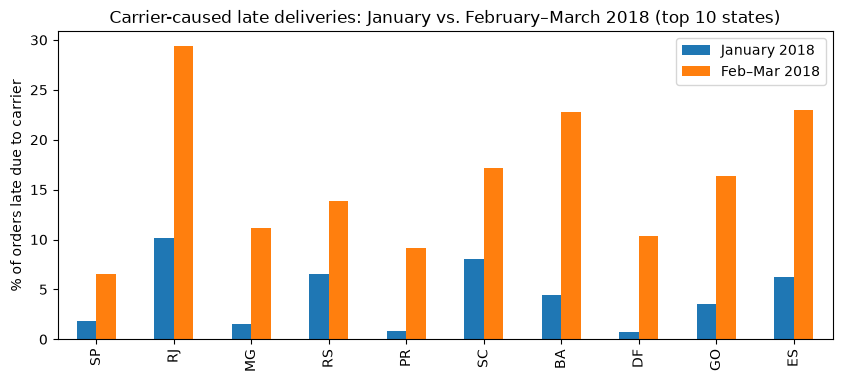

In [6]:
states = q("""
SELECT
    customer_state,
    COUNT(*) FILTER (WHERE purchase_month = '2018-01-01')                     AS jan_orders,
    ROUND(100.0 * COUNT(*) FILTER (WHERE purchase_month = '2018-01-01' AND delay_cause = 'carrier')
        / NULLIF(COUNT(*) FILTER (WHERE purchase_month = '2018-01-01'), 0), 1)  AS jan_carrier_late_pct,
    COUNT(*) FILTER (WHERE purchase_month IN ('2018-02-01', '2018-03-01'))    AS febmar_orders,
    ROUND(100.0 * COUNT(*) FILTER (WHERE purchase_month IN ('2018-02-01', '2018-03-01') AND delay_cause = 'carrier')
        / NULLIF(COUNT(*) FILTER (WHERE purchase_month IN ('2018-02-01', '2018-03-01')), 0), 1) AS febmar_carrier_late_pct
FROM analytics.fct_order_delivery
GROUP BY customer_state
ORDER BY febmar_orders DESC
LIMIT 10
""")

ax = states.plot(x="customer_state", y=["jan_carrier_late_pct", "febmar_carrier_late_pct"],
                 kind="bar", figsize=(10, 4))
ax.set_title("Carrier-caused late deliveries: January vs. February–March 2018 (top 10 states)")
ax.set_ylabel("% of orders late due to carrier")
ax.set_xlabel("")
ax.legend(["January 2018", "Feb–Mar 2018"])
ax.figure.savefig(PROJECT_ROOT / "docs" / "carrier_late_by_state.png", dpi=150, bbox_inches="tight")

states

In [7]:
from scipy.stats import spearmanr

states["increase_pts"] = states["febmar_carrier_late_pct"] - states["jan_carrier_late_pct"]

rho, p_value = spearmanr(states["jan_carrier_late_pct"], states["increase_pts"])
print(f"Spearman correlation between January rate and Feb–Mar increase: {rho:.2f} (p = {p_value:.2f})")

states[["customer_state", "jan_carrier_late_pct", "febmar_carrier_late_pct", "increase_pts"]]

Spearman correlation between January rate and Feb–Mar increase: 0.31 (p = 0.38)


,customer_state,jan_carrier_late_pct,febmar_carrier_late_pct,increase_pts
0,SP,1.8,6.5,4.7
1,RJ,10.2,29.4,19.2
2,MG,1.5,11.2,9.7
3,RS,6.5,13.9,7.4
4,PR,0.8,9.1,8.3
5,SC,8.0,17.2,9.2
6,BA,4.4,22.8,18.4
7,DF,0.7,10.4,9.7
8,GO,3.5,16.4,12.9
9,ES,6.2,23.0,16.8


**Finding:** The February–March 2018 carrier spike hit **every one of the top 10
states** — no region escaped, which points to a network-wide transport problem
rather than a local one.

- **Rio de Janeiro (RJ) has a structural problem on top of the spike:** 10.2%
  carrier-late even in a normal month (January), rising to 29.4% in Feb–Mar —
  almost 1 in 3 orders. As the second-largest market, this matters.
- **São Paulo (SP) performs best** despite the highest volume (1.8% → 6.5%),
  plausibly because most sellers are based there and delivery distances are short.
- **Some states were hit hard from a low base:** Bahia (BA) rose from 4.4% to
  22.8% (+18 points); Paraná (PR) and Distrito Federal (DF) rose roughly 11–15×,
  though only +8 to +10 points in absolute terms.
- **Did already-weak states suffer more?** A Spearman rank correlation between
  January rates and the Feb–Mar increase was weak and not significant
  (ρ = 0.31, p = 0.38, n = 10). The spike hit states broadly regardless of
  their normal performance.

**Recommendation:** treat RJ as a separate, structural issue (route, carrier or
estimate review), distinct from the temporary network-wide disruption.

## 5. Do late deliveries get lower review scores?

,delivery,orders,avg_review,pct_one_star
0,Late,6381,2.27,53.8
1,On time,89443,4.29,6.6


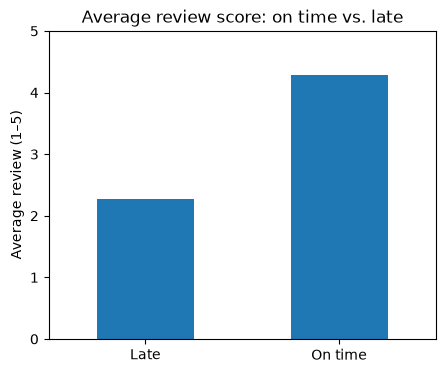

In [8]:
reviews = q("""
SELECT
    CASE WHEN is_late THEN 'Late' ELSE 'On time' END   AS delivery,
    COUNT(*)                                            AS orders,
    ROUND(AVG(review_score), 2)                         AS avg_review,
    ROUND(100.0 * AVG((review_score = 1)::int), 1)      AS pct_one_star
FROM analytics.fct_order_delivery
WHERE review_score IS NOT NULL
GROUP BY 1
""")

ax = reviews.plot(x="delivery", y="avg_review", kind="bar", legend=False, figsize=(5, 4), rot=0)
ax.set_title("Average review score: on time vs. late")
ax.set_ylabel("Average review (1–5)")
ax.set_xlabel("")
ax.set_ylim(0, 5)
ax.figure.savefig(PROJECT_ROOT / "docs" / "reviews_late_vs_on_time.png", dpi=150, bbox_inches="tight")

reviews

**Finding:** Delivery timeliness is one of the strongest drivers of customer
satisfaction in this data. Reviews are on a 1–5 scale.

- **On-time orders** average **4.29**, and only **6.6%** receive a 1-star review.
- **Late orders** average **2.27** — about 2 points lower — and **53.8%** receive
  a 1-star review, roughly 8× the on-time rate.

Overall review scores are good (~4.2), because most orders arrive on time; the
dissatisfaction is concentrated in late orders. More than half of late customers
give the lowest possible rating.

**Caveats:** this is an association, not proof of cause — a late order may also
have other problems (damaged parcel, wrong item). Likewise, the 6.6% of 1-star
reviews on on-time orders show that other factors, such as product quality,
also drive dissatisfaction.

## 6. Do customers come back less often after a late first order?

In [9]:
from statsmodels.stats.proportion import proportions_ztest

retention = q("""
SELECT
    CASE WHEN first_order_late THEN 'Late first order' ELSE 'On-time first order' END AS first_order,
    COUNT(*)                                        AS customers,
    SUM(is_repeat_customer::int)                    AS repeat_customers,
    ROUND(100.0 * AVG(is_repeat_customer::int), 2)  AS repeat_rate_pct
FROM analytics.dim_customers
WHERE first_order_at < '2018-03-01'
GROUP BY 1
""")

z_stat, p_value = proportions_ztest(
    count=retention["repeat_customers"],
    nobs=retention["customers"]
)
print(f"Two-proportion z-test: z = {z_stat:.2f}, p = {p_value:.4f}")

retention

Two-proportion z-test: z = -2.74, p = 0.0062


,first_order,customers,repeat_customers,repeat_rate_pct
0,Late first order,3678,115,3.13
1,On-time first order,51845,2094,4.04


**Finding:** Customers whose first order arrived late were less likely to order
again: **3.13%** vs. **4.04%** for customers with an on-time first order — about
**23% lower** in relative terms. A two-proportion z-test shows the difference is
statistically significant (z = −2.74, p = 0.006), so it is unlikely to be due
to chance.

Only customers whose first order was before March 2018 are included, so everyone
had at least ~6 months to return.

**Caveats:** repeat rates are low for everyone (~4%), so the absolute gap is
small. And this is an association: late deliveries are concentrated in certain
states (e.g. RJ), so part of the gap could reflect location rather than lateness
itself. A within-state comparison would be the next step.

## 7. Does a slow first delivery reduce repeat orders — even when it arrives on time?

,first_delivery_wait,all_customers,repeat_rate_all,on_time_customers,repeat_rate_on_time_only
0,1: up to 1 week,13876,4.24,13876,4.24
1,2: 1-2 weeks,23116,4.10,23072,4.10
2,3: 2-3 weeks,10803,3.88,10568,3.90
3,4: over 3 weeks,7728,3.27,4329,3.40


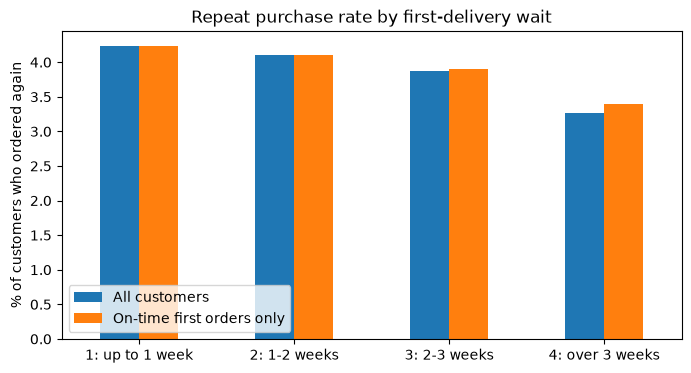

In [10]:
speed = q("""
SELECT
    CASE
        WHEN first_order_delivery_days <= 7  THEN '1: up to 1 week'
        WHEN first_order_delivery_days <= 14 THEN '2: 1-2 weeks'
        WHEN first_order_delivery_days <= 21 THEN '3: 2-3 weeks'
        ELSE '4: over 3 weeks'
    END                                                   AS first_delivery_wait,
    COUNT(*)                                              AS all_customers,
    ROUND(100.0 * AVG(is_repeat_customer::int), 2)        AS repeat_rate_all,
    COUNT(*) FILTER (WHERE NOT first_order_late)          AS on_time_customers,
    ROUND(100.0 * AVG(is_repeat_customer::int) FILTER (WHERE NOT first_order_late), 2)
                                                          AS repeat_rate_on_time_only
FROM analytics.dim_customers
WHERE first_order_at < '2018-03-01'
GROUP BY 1
ORDER BY 1
""")

ax = speed.plot(x="first_delivery_wait", y=["repeat_rate_all", "repeat_rate_on_time_only"],
                kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Repeat purchase rate by first-delivery wait")
ax.set_ylabel("% of customers who ordered again")
ax.set_xlabel("")
ax.set_ylim(0, None)
ax.legend(["All customers", "On-time first orders only"], loc="lower left")
ax.figure.savefig(PROJECT_ROOT / "docs" / "repeat_rate_by_delivery_wait.png", dpi=150, bbox_inches="tight")

speed

**Finding:** The longer customers waited for their first delivery, the less
likely they were to order again — **even when the order arrived on time**.
Among on-time first orders, the repeat rate falls from **4.24%** (delivered
within a week) to **3.40%** (over three weeks) — about 20% lower.

This means "on time" is not the same as "good enough": 4,329 customers waited
over three weeks yet were counted as on time, because the promised date itself
was that far out. Delivery speed affects retention independently of lateness.

**Caveat:** the differences between neighbouring groups are small, and longer
deliveries may also go to more remote regions, which could have lower repeat
rates for other reasons.

## 8. Which customer segments hold the revenue?

,rfm_segment,customers,avg_spend,total_revenue,pct_of_revenue
0,recent_high_value,22468,261.22,5869042.0,38.1
1,lapsed_high_value,21739,264.33,5746241.0,37.3
2,lapsed_low_value,23679,63.81,1511048.0,9.8
3,recent_low_value,22663,63.00,1427876.0,9.3
4,repeat,2801,308.53,864187.0,5.6


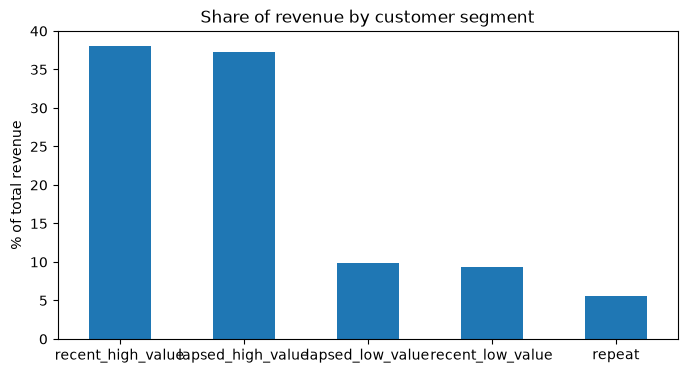

In [11]:
segments = q("""
SELECT
    rfm_segment,
    COUNT(*)                          AS customers,
    ROUND(AVG(total_spend), 2)        AS avg_spend,
    ROUND(SUM(total_spend), 0)        AS total_revenue,
    ROUND(100.0 * SUM(total_spend) / SUM(SUM(total_spend)) OVER (), 1) AS pct_of_revenue
FROM analytics.customer_segments
GROUP BY rfm_segment
ORDER BY total_revenue DESC
""")

ax = segments.plot(x="rfm_segment", y="pct_of_revenue", kind="bar", legend=False, figsize=(8, 4), rot=0)
ax.set_title("Share of revenue by customer segment")
ax.set_ylabel("% of total revenue")
ax.set_xlabel("")
ax.figure.savefig(PROJECT_ROOT / "docs" / "revenue_by_segment.png", dpi=150, bbox_inches="tight")

segments

**Finding:** Customers were grouped by how recently they bought, how much they
spent, and whether they ever ordered more than once (an adapted RFM model —
standard frequency scoring doesn't work here because 97% of customers bought
only once).

- **The two high-value segments generate ~75% of revenue** (38% recent, 37%
  lapsed), so CRM effort should focus there.
- **Repeat customers are the most valuable individuals** (avg. 309 BRL — almost
  double the overall average of ~165 BRL), but they are only 3% of customers
  and 5.6% of revenue. The marketplace's most valuable customer type barely exists.
- **The biggest opportunity is `recent_high_value`:** 22,468 customers who
  recently spent a lot but haven't returned yet. Converting just 1% of them to
  a second order would add roughly 59,000 BRL.

**Recommended actions by segment:** reward repeat customers; nurture recent
high-value customers toward a second purchase; test win-back offers on lapsed
high-value customers; keep spend low on lapsed low-value customers.

## 9. Are delivery estimates too cautious?

In [12]:
q("""
SELECT
    ROUND(AVG(estimated_delivery_date - purchased_at::date), 1)   AS avg_promised_days,
    ROUND(AVG(delivery_days), 1)                                  AS avg_actual_days,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY days_late)        AS median_days_vs_promise,
    ROUND(100.0 * AVG((days_late <= -7)::int), 1)                 AS pct_7plus_days_early
FROM analytics.fct_order_delivery
""")

,avg_promised_days,avg_actual_days,median_days_vs_promise,pct_7plus_days_early
0,24.4,12.5,-12.0,78.9


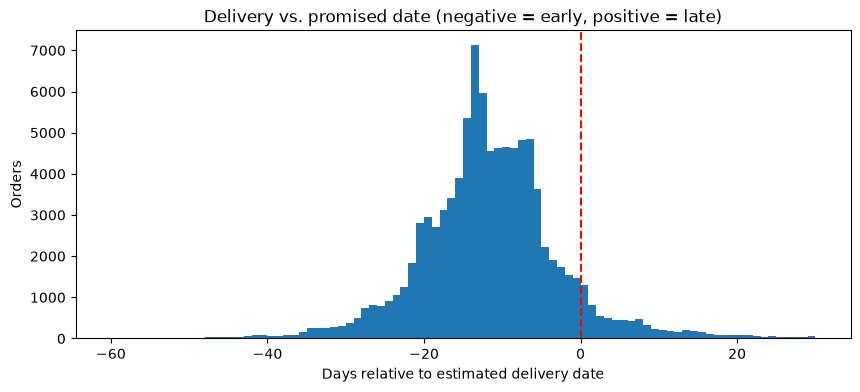

In [13]:
   dist = q("""
   SELECT days_late
   FROM analytics.fct_order_delivery
   WHERE days_late BETWEEN -60 AND 30
   """)

   ax = dist["days_late"].plot(kind="hist", bins=90, figsize=(10, 4))
   ax.axvline(0, color="red", linestyle="--")
   ax.set_title("Delivery vs. promised date (negative = early, positive = late)")
   ax.set_xlabel("Days relative to estimated delivery date")
   ax.set_ylabel("Orders")
   ax.figure.savefig(PROJECT_ROOT / "docs" / "delivery_vs_promise.png", dpi=150, bbox_inches="tight")

**Finding:** Delivery estimates are very conservative. On average Olist promised
delivery in **24.4 days**, but orders actually arrived in **12.5 days**. The
typical order arrived **12 days early**, and **78.9%** arrived at least a week
before the promised date.

This has three implications:
1. The ~93% on-time rate looks good partly because the promise is so generous —
   late orders are the ones that missed a very large buffer.
2. It explains Question 7: customers can wait over three weeks and still count as
   "on time", and slower first deliveries are linked to lower repeat purchasing.
3. **Trade-off:** shortening estimates could make the offer more attractive at
   checkout (not testable with this data), but would also turn some on-time orders
   into late ones — and 53.8% of late orders receive a 1-star review. Estimates
   should be tightened carefully, e.g. per region based on actual delivery times,
   and validated with an A/B test measuring both conversion and review scores.